# Graph Types and NSPPK Vectorization

This notebook follows one small labeled graph as it moves through four NetworkX graph types: a `MultiGraph`, a directed `MultiDiGraph`, a simple `DiGraph`, and a simple undirected `Graph`. Each version is drawn with the same node positions, then encoded with the same NSPPK settings so the feature vectors can be compared.

The sequence shows which information each representation preserves: parallel edges, arc directions, and the collapse back to undirected connectivity.

## Imports and drawing helper

The custom drawing helper offsets parallel edges and uses arrowheads for directed arcs. This keeps the four views comparable while making parallel edges and directions visible.

In [1]:
from pathlib import Path
import sys

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(candidate for candidate in REPO_CANDIDATES if (candidate / 'src').exists())
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D
from nsppk import NSPPK

NODE_POS = {
    'A': (-1.0, 0.0),
    'B': (0.0, 1.0),
    'C': (1.0, 0.0),
    'D': (0.0, -1.0),
}
NODE_LABELS = {'A': 'C', 'B': 'N', 'C': 'O', 'D': 'S'}
NODE_COLORS = {'C': '#6ED3FF', 'N': '#A78BFA', 'O': '#FF6B6B', 'S': '#FFD166'}
EDGE_COLORS = {
    'single': '#344054',
    'aromatic': '#7C3AED',
    'double': '#0F766E',
    'triple': '#C2410C',
}


def draw_graph_variant(graph, ax, title):
    """Draw graph variants on a shared layout, including keyed parallel edges."""
    is_directed = graph.is_directed()
    if graph.is_multigraph():
        edges = list(graph.edges(keys=True, data=True))
    else:
        edges = [(u, v, None, data) for u, v, data in graph.edges(data=True)]

    pair_counts = {}
    for u, v, key, data in edges:
        group = (u, v) if is_directed else frozenset((u, v))
        offset = pair_counts.get(group, 0)
        pair_counts[group] = offset + 1
        rad = 0.0 if offset == 0 else 0.22 * ((offset + 1) // 2) * (1 if offset % 2 else -1)
        edge_label = data.get('label', 'unlabeled')
        patch = FancyArrowPatch(
            NODE_POS[u], NODE_POS[v],
            arrowstyle='-|>' if is_directed else '-',
            mutation_scale=16,
            linewidth=2.2,
            color=EDGE_COLORS.get(edge_label, '#667085'),
            connectionstyle=f'arc3,rad={rad}',
            shrinkA=18,
            shrinkB=18,
            zorder=1,
        )
        ax.add_patch(patch)
        x_mid = (NODE_POS[u][0] + NODE_POS[v][0]) / 2
        y_mid = (NODE_POS[u][1] + NODE_POS[v][1]) / 2 + rad * 0.45
        ax.text(x_mid, y_mid, str(edge_label), fontsize=8, ha='center', va='center',
                bbox={'boxstyle': 'round,pad=0.18', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9},
                zorder=3)

    for node, (x, y) in NODE_POS.items():
        label = NODE_LABELS[node]
        ax.scatter([x], [y], s=950, color=NODE_COLORS[label], edgecolor='#1D2939', linewidth=1.5, zorder=4)
        ax.text(x, y, f'{node}\n{label}', ha='center', va='center', fontsize=11, weight='bold', zorder=5)

    ax.set_title(f'{title}\n{type(graph).__name__}: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges')
    ax.set_xlim(-1.55, 1.55)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect('equal')
    ax.axis('off')


EDGE_LEGEND = [
    Line2D([0], [0], color=color, lw=2.5, label=label)
    for label, color in EDGE_COLORS.items()
]

## 1. Start with a multigraph

The base graph has four labeled nodes and two distinct `A–B` edges. The parallel edges have different discrete labels, so the multigraph retains both contributions.

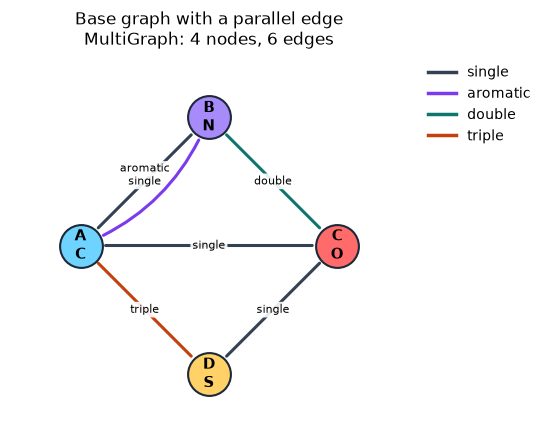

[('A', 'B', 'single_ab', 'single'),
 ('A', 'B', 'aromatic_ab', 'aromatic'),
 ('A', 'D', 'triple_da', 'triple'),
 ('A', 'C', 'single_ac', 'single'),
 ('B', 'C', 'double_bc', 'double'),
 ('C', 'D', 'single_cd', 'single')]

In [2]:
base_multi = nx.MultiGraph()
for node, label in NODE_LABELS.items():
    base_multi.add_node(node, label=label)

base_multi.add_edge('A', 'B', key='single_ab', label='single')
base_multi.add_edge('A', 'B', key='aromatic_ab', label='aromatic')
base_multi.add_edge('B', 'C', key='double_bc', label='double')
base_multi.add_edge('C', 'D', key='single_cd', label='single')
base_multi.add_edge('D', 'A', key='triple_da', label='triple')
base_multi.add_edge('A', 'C', key='single_ac', label='single')

fig, ax = plt.subplots(figsize=(6, 5))
draw_graph_variant(base_multi, ax, 'Base graph with a parallel edge')
ax.legend(handles=EDGE_LEGEND, loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False)
plt.show()

list(base_multi.edges(keys=True, data='label'))

## 2. Orient the same keyed edges

Now each keyed edge becomes an arc. The two parallel `A–B` edges remain distinct and point from `A` to `B`. Other arcs include both directions across the motif, while the underlying undirected connectivity stays the same.

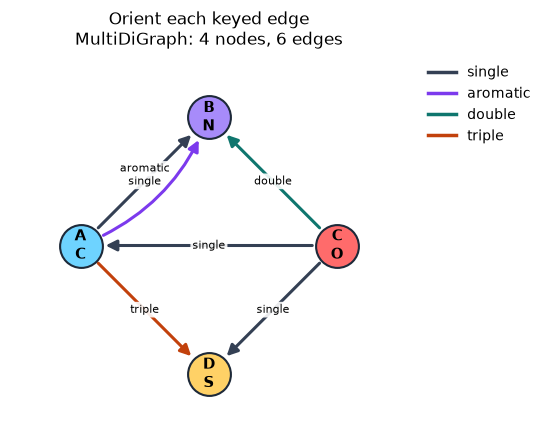

In [3]:
arc_endpoints = {
    'single_ab': ('A', 'B'),
    'aromatic_ab': ('A', 'B'),
    'double_bc': ('C', 'B'),
    'single_cd': ('C', 'D'),
    'triple_da': ('A', 'D'),
    'single_ac': ('C', 'A'),
}

directed_multi = nx.MultiDiGraph()
directed_multi.add_nodes_from((node, dict(data)) for node, data in base_multi.nodes(data=True))
for u, v, key, data in base_multi.edges(keys=True, data=True):
    source, target = arc_endpoints[key]
    directed_multi.add_edge(source, target, key=key, **dict(data))

fig, ax = plt.subplots(figsize=(6, 5))
draw_graph_variant(directed_multi, ax, 'Orient each keyed edge')
ax.legend(handles=EDGE_LEGEND, loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False)
plt.show()

## 3. Collapse parallel arcs to a simple directed graph

A `DiGraph` can hold only one edge per ordered node pair. When parallel arcs share a direction, this conversion combines their labels into one tuple. The reverse `B → C` arc remains a separate directed edge.

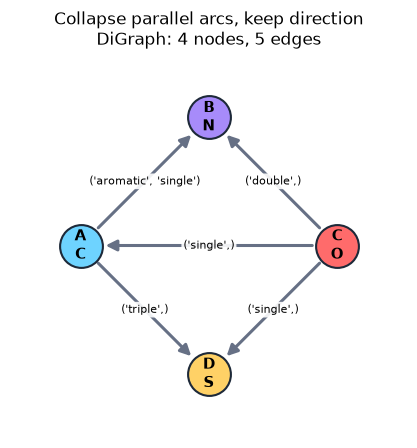

[('A', 'B', ('aromatic', 'single')),
 ('A', 'D', ('triple',)),
 ('C', 'A', ('single',)),
 ('C', 'B', ('double',)),
 ('C', 'D', ('single',))]

In [4]:
directed_simple = nx.DiGraph()
directed_simple.add_nodes_from((node, dict(data)) for node, data in directed_multi.nodes(data=True))
labels_by_arc = {}
for source, target, key, data in directed_multi.edges(keys=True, data=True):
    labels_by_arc.setdefault((source, target), []).append(data['label'])
for (source, target), labels in labels_by_arc.items():
    directed_simple.add_edge(source, target, label=tuple(sorted(labels)))

fig, ax = plt.subplots(figsize=(6, 5))
draw_graph_variant(directed_simple, ax, 'Collapse parallel arcs, keep direction')
plt.show()

[(u, v, data['label']) for u, v, data in directed_simple.edges(data=True)]

## 4. Drop direction and collapse endpoint pairs

Finally, convert to a simple undirected `Graph`. Arcs that connect the same pair of nodes are grouped together; the combined label records the edge labels that were present before collapsing.

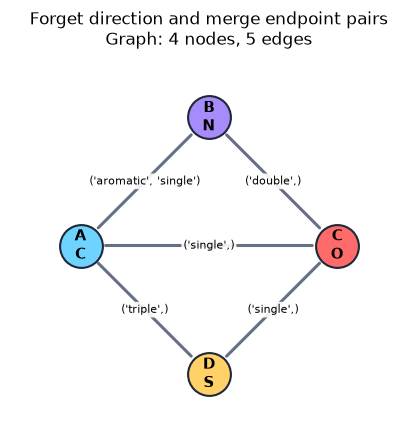

In [5]:
undirected_simple = nx.Graph()
undirected_simple.add_nodes_from((node, dict(data)) for node, data in directed_simple.nodes(data=True))
labels_by_pair = {}
for source, target, data in directed_simple.edges(data=True):
    pair = frozenset((source, target))
    labels_by_pair.setdefault(pair, []).extend(data['label'])
for pair, labels in labels_by_pair.items():
    u, v = sorted(pair)
    undirected_simple.add_edge(u, v, label=tuple(sorted(labels)))

fig, ax = plt.subplots(figsize=(6, 5))
draw_graph_variant(undirected_simple, ax, 'Forget direction and merge endpoint pairs')
plt.show()

## Vectorize every version with NSPPK

The estimator uses one shared configuration and hashes each graph independently. For directed graphs, NSPPK uses the undirected projection for distances and neighborhoods but keeps direction in its hash patterns. Each result below is one graph-level feature vector with `2 ** nbits` columns.

In [6]:
graph_variants = [
    ('MultiGraph', base_multi),
    ('MultiDiGraph', directed_multi),
    ('DiGraph', directed_simple),
    ('Graph', undirected_simple),
]

vectorizer = NSPPK(radius=1, distance=3, connector=1, nbits=8, dense=False, parallel=False)
feature_vectors = {
    name: vectorizer.transform([graph]).toarray()[0]
    for name, graph in graph_variants
}

summary = pd.DataFrame([
    {
        'variant': name,
        'graph type': type(graph).__name__,
        'edges': graph.number_of_edges(),
        'vector width': len(feature_vectors[name]),
        'nonzero features': int(np.count_nonzero(feature_vectors[name])),
        'feature sum': float(feature_vectors[name].sum()),
    }
    for name, graph in graph_variants
]).set_index('variant')
summary

,graph type,edges,vector width,nonzero features,feature sum
variant,,,,,
MultiGraph,MultiGraph,6,256,85,192.0
MultiDiGraph,MultiDiGraph,6,256,87,192.0
DiGraph,DiGraph,5,256,82,182.0
Graph,Graph,5,256,91,182.0


In [7]:
# Show a compact view of the vectors as feature-index/value pairs.
for name, _ in graph_variants:
    vector = feature_vectors[name]
    active = np.flatnonzero(vector)
    top = sorted(active, key=lambda idx: (-vector[idx], idx))[:12]
    print(f'{name}: shape={vector.shape}, active={len(active)}')
    print({int(idx): float(vector[idx]) for idx in top})
    print()

MultiGraph: shape=(256,), active=85
{1: 12.0, 98: 7.0, 111: 7.0, 11: 6.0, 31: 6.0, 70: 5.0, 122: 5.0, 135: 5.0, 187: 5.0, 0: 4.0, 19: 4.0, 250: 4.0}

MultiDiGraph: shape=(256,), active=87
{1: 12.0, 47: 6.0, 87: 6.0, 107: 6.0, 187: 6.0, 98: 5.0, 155: 5.0, 242: 5.0, 0: 4.0, 31: 4.0, 38: 4.0, 43: 4.0}

DiGraph: shape=(256,), active=82
{1: 10.0, 130: 8.0, 127: 7.0, 171: 6.0, 175: 6.0, 210: 6.0, 23: 5.0, 0: 4.0, 2: 4.0, 3: 4.0, 51: 4.0, 70: 4.0}

Graph: shape=(256,), active=91
{1: 10.0, 122: 7.0, 175: 7.0, 179: 6.0, 182: 6.0, 203: 6.0, 0: 4.0, 15: 4.0, 170: 4.0, 19: 3.0, 43: 3.0, 50: 3.0}



### Compare the resulting vectors

This heatmap shows the feature values across the four graph versions. Feature columns are hashed IDs, so a column is not a human-readable motif label. Differences show how preserving or collapsing direction and parallel edges changes the NSPPK representation.

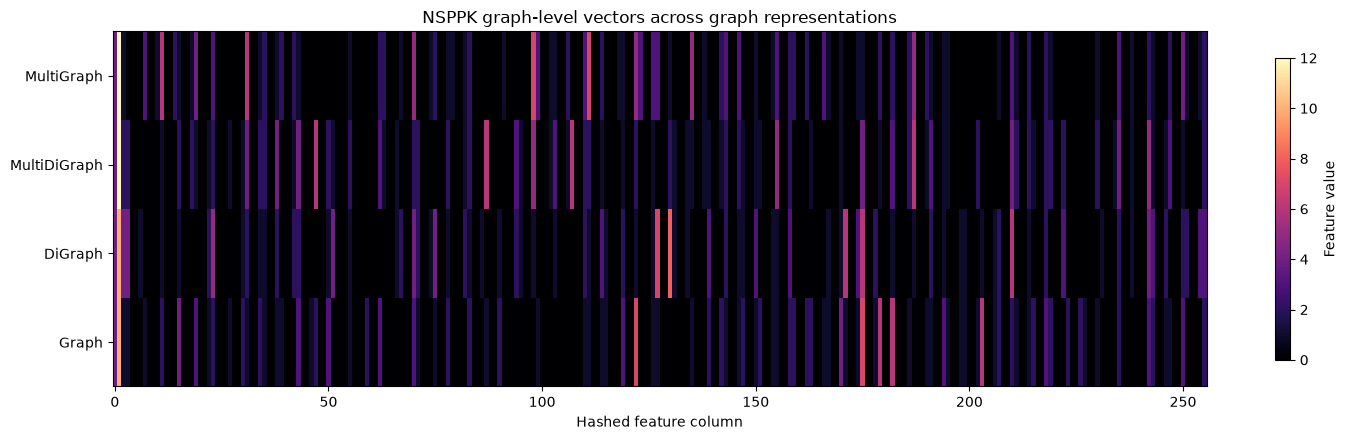

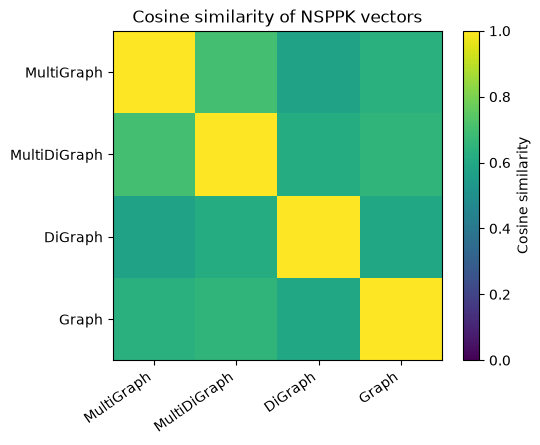

In [8]:
vector_matrix = np.vstack([feature_vectors[name] for name, _ in graph_variants])
fig, ax = plt.subplots(figsize=(15, 4.5))
image = ax.imshow(vector_matrix, aspect='auto', interpolation='nearest', cmap='magma')
ax.set_yticks(range(len(graph_variants)), [name for name, _ in graph_variants])
ax.set_xlabel('Hashed feature column')
ax.set_title('NSPPK graph-level vectors across graph representations')
fig.colorbar(image, ax=ax, label='Feature value', shrink=0.85)
plt.tight_layout()
plt.show()

from sklearn.metrics.pairwise import cosine_similarity
similarities = cosine_similarity(vector_matrix)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(similarities, vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(range(len(graph_variants)), [name for name, _ in graph_variants], rotation=35, ha='right')
ax.set_yticks(range(len(graph_variants)), [name for name, _ in graph_variants])
ax.set_title('Cosine similarity of NSPPK vectors')
fig.colorbar(image, ax=ax, label='Cosine similarity')
plt.tight_layout()
plt.show()

## Takeaways

- The `MultiGraph` keeps two separately labeled `A–B` edges; the `MultiDiGraph` preserves both edges and their orientations.
- The simple `DiGraph` merges parallel arcs with the same ordered endpoints, while the `Graph` drops orientation and merges endpoint pairs.
- Every stage has the same node set and underlying connected motif. The corresponding NSPPK vectors make the effects of those representation choices visible.
- Hashed columns may collide, so compare the full vector patterns and the similarity view rather than treating any one column as a named graph property.